# Leaf area: CLM vs LPJ-GUESS

**Question.** Our future BVOC emissions rise much more than Tang et al. (2023)'s. In MEGAN, about half of that rise is the leaf-area factor γL: CLM's LAI roughly doubles from PD to FUT in the LCC-modified cells. Does LPJ-GUESS (the model behind our LCC cover and Tang's emissions) simulate the same LAI and the same LAI change?

| | LPJ-GUESS | CLM (ours) |
|---|---|---|
| PD | 1971–2000 mean (`lai1971to2000.txt`, monthly `mlai_pft_avg_1971_2000_monthly_mean.out`) | `CTRL_PD`, `LCC_PD`, 2001–2025 (year-2000 forcing) |
| FUT | 2071–2100, GFDL-ESM4 SSP5-8.5 (`GFDL-ESM4_SPP585_lai2071to2100.txt`, monthly `mlai_pft_avg_2071_2100_monthly_mean.out`) | `CTRL_FUT`, `LCC_FUT`, 2001–2025 (year-2100 forcing) |
| Vegetation | dynamic (its own PFTs and productivity) | `CTRL_*`: CLM 2000 PFTs; `LCC_*`: PFT fractions from LPJ-GUESS 2071–2100 |
| LAI field | `Total` column = grid-cell LAI (natural + peatland stands, area-weighted; checked below) | `TLAI`, grid-cell mean of the patches' LAI |

**Matching pairs.** LPJ-GUESS PD → FUT includes vegetation, climate and CO₂ change, like **CTRL_PD → LCC_FUT** (Tang's "standard"). **CTRL_PD → CTRL_FUT** keeps CLM's PFTs: climate + CO₂ only.

**Differences to keep in mind**
- **Periods:** LPJ-GUESS 30-yr means centred on 1985 and 2085; ours 25 years of year-2000 and year-2100 forcing. The PD gap (~15 yr of warming and CO₂) makes the LPJ-GUESS PD LAI a bit lower than a 2000 value would be (b).
- **Which LPJ-GUESS historical climate** (bias-corrected GFDL-ESM4 historical or observations) the 1971–2000 file used is not documented in the data folder (c).
- **Grid:** LPJ-GUESS 0.5° over the tundra + boreal gridlist (45.75–83.25°N) is averaged onto the CLM 1.9° × 2.5° grid (cos-lat weighted mean of the 0.5° cells in each CLM cell). CLM cells with < 50 % of their 0.5° cells covered by LPJ-GUESS are left out ("common cells").
- **CLM `TLAI`:** the history-file grid-cell mean over the vegetated patches; whether non-vegetated landunits enter it as zero was not checked (c). It differs from LPJ-GUESS's stand-weighted `Total`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point

REPO = Path("/cluster/home/adelez/BOREAL-FOREST-EXPANSION")
sys.path.insert(0, str(REPO / "src"))
from boreal_forest_expansion.plotting import forcing_maps as fm
from boreal_forest_expansion.plotting import palette as pal

OUT = REPO / "diagnostics" / "lai-clm-vs-lpjguess" / "clm_vs_lpjguess_lai_outputs"
OUT.mkdir(parents=True, exist_ok=True)
LPJ = Path("/nird/datapeak/NS9188K/adelez/BRL-FRST-XPSN/data/edit-surfdata/LPJ-GUESS")
FILES = {
    ("PD", "annual"): LPJ / "lai1971to2000.txt",
    ("FUT", "annual"): LPJ / "GFDL-ESM4_SPP585_lai2071to2100.txt",   # "SPP" is in the supplied filename
    ("PD", "monthly"): LPJ / "mlai_pft_avg_1971_2000_monthly_mean.out",
    ("FUT", "monthly"): LPJ / "mlai_pft_avg_2071_2100_monthly_mean.out",
}
Y0, Y1 = 2001, 2025
RUNS = ["CTRL_PD", "CTRL_FUT", "LCC_PD", "LCC_FUT"]
EXTENT_LAT = 45.0
JJA = [6, 7, 8]
MIN_COVER = 0.5   # CLM cell kept if >= 50 % of its 0.5-degree cells are in the LPJ-GUESS data

## 1. LPJ-GUESS LAI

`Total` is the grid-cell LAI. In the annual files it equals the peatland-fraction-weighted mean of `Natural_sum` and `Peatland_sum`, not their sum (first row: 2.649 natural, 1.546 peatland, total 2.109); checked below. The monthly files can repeat their header inside the table (data README), so those rows are dropped.

In [2]:
def read_table(path):
    df = pd.read_csv(path, sep=r"\s+", dtype=str)
    df = df[df["Lon"] != "Lon"]                      # repeated header rows
    return df.apply(pd.to_numeric, errors="raise")

def to_grid(df, extra=()):
    idx = ["Lat", "Lon", *extra]
    if df.duplicated(idx).any():
        raise ValueError("duplicate rows")
    da = df.set_index(idx)["Total"].to_xarray().rename({"Lat": "lat", "Lon": "lon"})
    return da

lpj = {}
tabs = {}
for (per, kind), path in FILES.items():
    df = read_table(path)
    tabs[per, kind] = df
    lpj[per, kind] = to_grid(df, ("Month",) if kind == "monthly" else ())
    print(f"{per:3s} {kind:7s} {path.name:42s} cells {len(df) // (12 if kind == 'monthly' else 1):6d}  "
          f"Total {float(df['Total'].min()):.2f}..{float(df['Total'].max()):.2f}")

# check: annual Total = weighted mean of the natural and peatland stands (weight = implied peat fraction in [0, 1])
for per in ("PD", "FUT"):
    df = tabs[per, "annual"]
    gap = df["Natural_sum"] - df["Peatland_sum"]
    ok = gap.abs() > 0.05
    w = ((df["Natural_sum"] - df["Total"]) / gap)[ok]
    print(f"{per}: implied peatland weight {w.min():.3f}..{w.max():.3f} (in [0, 1] -> Total is a weighted mean); "
          f"Total <= max(stands): {bool((df['Total'] <= df[['Natural_sum', 'Peatland_sum']].max(axis=1) + 1e-3).all())}")

PD  annual  lai1971to2000.txt                          cells  16750  Total 0.00..4.11
FUT annual  GFDL-ESM4_SPP585_lai2071to2100.txt         cells  16750  Total 0.00..4.91
PD  monthly mlai_pft_avg_1971_2000_monthly_mean.out    cells  16714  Total 0.00..4.15
FUT monthly mlai_pft_avg_2071_2100_monthly_mean.out    cells  16750  Total 0.00..4.85
PD: implied peatland weight 0.000..1.000 (in [0, 1] -> Total is a weighted mean); Total <= max(stands): True
FUT: implied peatland weight 0.000..1.000 (in [0, 1] -> Total is a weighted mean); Total <= max(stands): True


**Is the annual file a mean or a peak?** Compare the annual `Total` with the mean and with the maximum of the 12 monthly values, cell by cell.

In [3]:
rows = []
for per in ("PD", "FUT"):
    ann = lpj[per, "annual"]
    mon = lpj[per, "monthly"]
    a, m = xr.align(ann, mon, join="inner")
    w = np.cos(np.deg2rad(a["lat"])) * xr.ones_like(a)
    valid = a.notnull() & m.notnull().all("Month")
    for name, x in [("annual file", a), ("monthly mean", m.mean("Month")), ("monthly max", m.max("Month"))]:
        rows.append(dict(period=per, quantity=name, mean=float((x * w).where(valid).sum() / w.where(valid).sum())))
    r_mean = float(np.corrcoef(a.where(valid).values[valid.values], m.mean("Month").values[valid.values])[0, 1])
    r_max = float(np.corrcoef(a.where(valid).values[valid.values], m.max("Month").values[valid.values])[0, 1])
    print(f"{per}: {int(valid.sum())} common cells; r(annual, monthly mean) = {r_mean:.3f}, r(annual, monthly max) = {r_max:.3f}")
pd.DataFrame(rows).pivot(index="quantity", columns="period", values="mean").round(3)

PD: 16714 common cells; r(annual, monthly mean) = 0.850, r(annual, monthly max) = 0.998
FUT: 16750 common cells; r(annual, monthly mean) = 0.840, r(annual, monthly max) = 0.996


period,FUT,PD
quantity,,
annual file,2.932,1.977
monthly max,2.925,1.962
monthly mean,1.877,1.171


## 2. LPJ-GUESS onto the CLM grid, and CLM `TLAI`

In [4]:
P = REPO / "data" / "processed-data" / "postprocessing"
clm = {}
for run in RUNS:
    with xr.open_dataset(P / f"{run}_lnd_LAND_{Y0}-{Y1}.nc") as ds:
        clm[run] = ds["TLAI"].load()
        if run == "CTRL_PD":
            landfrac = ds["landfrac"].load()
glat, glon = clm["CTRL_PD"]["lat"].values, clm["CTRL_PD"]["lon"].values

def to_clm_grid(da):
    """Cos-lat weighted mean of the 0.5-degree cells in each CLM cell, + covered fraction."""
    lat_e = np.concatenate([[-90], (glat[1:] + glat[:-1]) / 2, [90]])
    dlon = glon[1] - glon[0]
    lon360 = np.mod(da["lon"].values, 360)
    il = np.digitize(da["lat"].values, lat_e) - 1
    jl = np.mod(np.round(lon360 / dlon).astype(int), glon.size)
    extra = [d for d in da.dims if d not in ("lat", "lon")]
    v = da.transpose(*extra, "lat", "lon").values
    w = np.cos(np.deg2rad(da["lat"].values))[:, None] * np.ones((1, lon360.size))
    I, J = np.meshgrid(il, jl, indexing="ij")
    shape = v.shape[:-2] + (glat.size, glon.size)
    s = np.zeros(shape); ws = np.zeros(shape)
    ok = np.isfinite(v)
    for k in np.ndindex(v.shape[:-2]):
        m = ok[k]
        np.add.at(s[k], (I[m], J[m]), (v[k] * w)[m])
        np.add.at(ws[k], (I[m], J[m]), w[m])
    # covered fraction: weight present / weight of all 0.5-degree cells in the CLM cell
    lat_h = np.arange(-89.75, 90, 0.5)
    full = np.zeros((glat.size, glon.size))
    il_h = np.digitize(lat_h, lat_e) - 1
    for i, latv in zip(il_h, lat_h):
        full[i, :] += np.cos(np.deg2rad(latv)) * (dlon / 0.5)
    cover = (ws.reshape(-1, glat.size, glon.size)[0] / full)
    coords = {**{d: da[d].values for d in extra}, "lat": glat, "lon": glon}
    out = xr.DataArray(np.where(ws > 0, s / np.where(ws > 0, ws, 1), np.nan), coords=coords, dims=(*extra, "lat", "lon"))
    return out, xr.DataArray(cover, coords={"lat": glat, "lon": glon}, dims=("lat", "lon"))

lpj_g = {}
for key, da in lpj.items():
    lpj_g[key], cov = to_clm_grid(da)
    if key == ("PD", "annual"):
        cover = cov
for key in lpj_g:
    if "Month" in lpj_g[key].dims:
        lpj_g[key] = lpj_g[key].rename(Month="month")

mask_ds = xr.open_dataset(REPO / "diagnostics" / "lcc-modified-cells" / "modified_cells.nc")
assert np.allclose(mask_ds["lat"], glat, atol=1e-9) and np.allclose(mask_ds["lon"], glon, atol=1e-9)
modified = mask_ds["modified"].astype(bool).assign_coords(lat=glat, lon=glon)
common = (cover >= MIN_COVER) & (landfrac > 0) & (cover["lat"] >= 45)
for key in lpj_g:   # keep only common cells for LPJ-GUESS
    lpj_g[key] = lpj_g[key].where(common)
print("common cells:", int(common.sum()), "| modified cells:", int(modified.sum()),
      "| modified cells that are common:", int((modified & common).sum()))

common cells: 857 | modified cells: 1161 | modified cells that are common: 844


In [5]:
DAYS = xr.DataArray([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31], coords={"month": np.arange(1, 13)}, dims="month")

def clim(da):                                   # monthly climatology of a CLM run
    return da.groupby("time.month").mean("time")

def summaries(mon):                             # mon: (month, lat, lon)
    # min_count: a cell without data stays NaN (sum() would make it 0)
    return {"annual mean": (mon * DAYS).sum("month", min_count=12) / DAYS.sum(),
            "JJA mean": (mon.sel(month=JJA) * DAYS.sel(month=JJA)).sum("month", min_count=3) / DAYS.sel(month=JJA).sum(),
            "seasonal max": mon.max("month")}

series = {}                                     # name -> monthly climatology (month, lat, lon)
series["LPJ-GUESS PD (1971–2000)"] = lpj_g["PD", "monthly"]
series["LPJ-GUESS FUT (2071–2100)"] = lpj_g["FUT", "monthly"]
for run in RUNS:
    series[run] = clim(clm[run]).where(common)

def wmean(da, where):
    w = np.cos(np.deg2rad(da["lat"])) * xr.ones_like(da)
    w = w.where(where & da.notnull(), 0)
    return float((da.fillna(0) * w).sum() / w.sum())

rows = []
for name, mon in series.items():
    for q, x in summaries(mon).items():
        for rname, reg in [("modified cells", modified & common), ("common cells ≥45°N", common)]:
            rows.append(dict(series=name, quantity=q, region=rname, LAI=wmean(x, reg)))
lai_tab = pd.DataFrame(rows)
lai_tab.to_csv(OUT / "lai_means_clm_vs_lpjguess.csv", index=False)
lai_tab.pivot_table(index=["region", "series"], columns="quantity", values="LAI", sort=False).round(2)

quantity                                      annual mean  JJA mean  \
region             series                                             
modified cells     LPJ-GUESS PD (1971–2000)          1.15      1.84   
                   LPJ-GUESS FUT (2071–2100)         1.88      2.88   
                   CTRL_PD                           1.15      1.77   
                   CTRL_FUT                          2.56      4.07   
                   LCC_PD                            1.11      1.65   
                   LCC_FUT                           2.40      3.66   
common cells ≥45°N LPJ-GUESS PD (1971–2000)          1.17      1.86   
                   LPJ-GUESS FUT (2071–2100)         1.89      2.89   
                   CTRL_PD                           1.18      1.79   
                   CTRL_FUT                          2.60      4.09   
                   LCC_PD                            1.13      1.68   
                   LCC_FUT                           2.44      3.69   

quantity                                      seasonal max  
region             series                                   
modified cells     LPJ-GUESS PD (1971–2000)           1.95  
                   LPJ-GUESS FUT (2071–2100)          2.94  
                   CTRL_PD                            2.08  
                   CTRL_FUT                           4.49  
                   LCC_PD                             1.93  
                   LCC_FUT                            4.02  
common cells ≥45°N LPJ-GUESS PD (1971–2000)           1.97  
                   LPJ-GUESS FUT (2071–2100)          2.95  
                   CTRL_PD                            2.11  
                   CTRL_FUT                           4.51  
                   LCC_PD                             1.95  
                   LCC_FUT                            4.05

## 3. PD → FUT change: LPJ-GUESS vs CLM

Ratio FUT / PD and difference of the region means above. CLM rows: the climate + CO₂ change on fixed CLM PFTs (CTRL_PD → CTRL_FUT), the same on the LCC PFTs (LCC_PD → LCC_FUT), and the "standard" change matching LPJ-GUESS (CTRL_PD → LCC_FUT).

In [6]:
PAIRS = {
    "LPJ-GUESS (veg + climate + CO₂)": ("LPJ-GUESS PD (1971–2000)", "LPJ-GUESS FUT (2071–2100)"),
    "CLM CTRL_PD → LCC_FUT (veg + climate + CO₂)": ("CTRL_PD", "LCC_FUT"),
    "CLM CTRL_PD → CTRL_FUT (climate + CO₂)": ("CTRL_PD", "CTRL_FUT"),
    "CLM LCC_PD → LCC_FUT (climate + CO₂)": ("LCC_PD", "LCC_FUT"),
    "CLM CTRL_FUT → LCC_FUT (veg, FUT)": ("CTRL_FUT", "LCC_FUT"),
    "CLM CTRL_PD → LCC_PD (veg, PD)": ("CTRL_PD", "LCC_PD"),
}
t = lai_tab.set_index(["series", "quantity", "region"])["LAI"]
rows = []
for name, (a, b) in PAIRS.items():
    for q in ("annual mean", "JJA mean", "seasonal max"):
        for reg in ("modified cells", "common cells ≥45°N"):
            pa, fb = t[a, q, reg], t[b, q, reg]
            rows.append(dict(change=name, quantity=q, region=reg, from_=pa, to=fb, diff=fb - pa, ratio=fb / pa))
chg = pd.DataFrame(rows).rename(columns={"from_": "from"})
chg.to_csv(OUT / "lai_change_clm_vs_lpjguess.csv", index=False)
chg[chg["region"] == "modified cells"].pivot_table(index="change", columns="quantity", values=["from", "to", "ratio"], sort=False).round(2)

from                        \
quantity                                    annual mean JJA mean seasonal max   
change                                                                          
LPJ-GUESS (veg + climate + CO₂)                    1.15     1.84         1.95   
CLM CTRL_PD → LCC_FUT (veg + climate + CO₂)        1.15     1.77         2.08   
CLM CTRL_PD → CTRL_FUT (climate + CO₂)             1.15     1.77         2.08   
CLM LCC_PD → LCC_FUT (climate + CO₂)               1.11     1.65         1.93   
CLM CTRL_FUT → LCC_FUT (veg, FUT)                  2.56     4.07         4.49   
CLM CTRL_PD → LCC_PD (veg, PD)                     1.15     1.77         2.08   

                                                     to                        \
quantity                                    annual mean JJA mean seasonal max   
change                                                                          
LPJ-GUESS (veg + climate + CO₂)                    1.88     2.88         2.94   
CLM CTRL_PD → LCC_FUT (veg + climate + CO₂)        2.40     3.66         4.02   
CLM CTRL_PD → CTRL_FUT (climate + CO₂)             2.56     4.07         4.49   
CLM LCC_PD → LCC_FUT (climate + CO₂)               2.40     3.66         4.02   
CLM CTRL_FUT → LCC_FUT (veg, FUT)                  2.40     3.66         4.02   
CLM CTRL_PD → LCC_PD (veg, PD)                     1.11     1.65         1.93   

                                                  ratio                        
quantity                                    annual mean JJA mean seasonal max  
change                                                                         
LPJ-GUESS (veg + climate + CO₂)                    1.64     1.57         1.51  
CLM CTRL_PD → LCC_FUT (veg + climate + CO₂)        2.08     2.07         1.93  
CLM CTRL_PD → CTRL_FUT (climate + CO₂)             2.22     2.30         2.15  
CLM LCC_PD → LCC_FUT (climate + CO₂)               2.16     2.21         2.08  
CLM CTRL_FUT → LCC_FUT (veg, FUT)                  0.94     0.90         0.89  
CLM CTRL_PD → LCC_PD (veg, PD)                     0.96     0.94         0.93

## 4. Seasonal cycle, modified cells

findfont: Failed to find font weight semibold, now using 700.


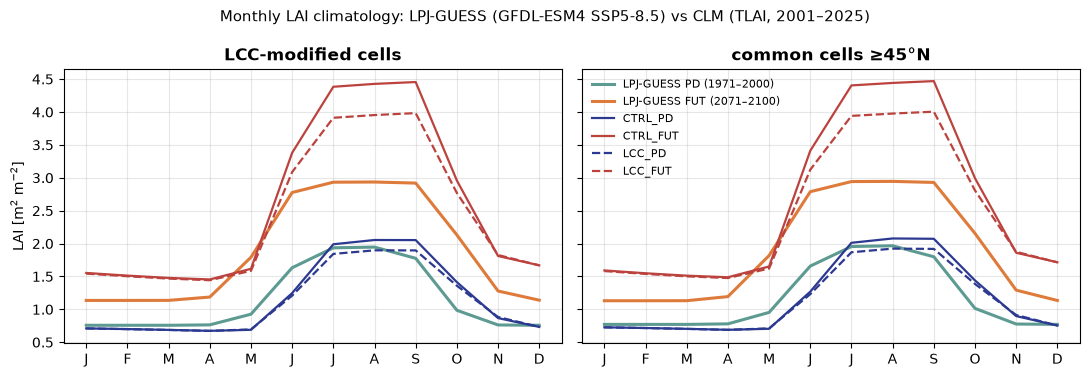

In [7]:
STYLE = {
    "LPJ-GUESS PD (1971–2000)": dict(color=pal.TEAL, ls="-", lw=2.2),
    "LPJ-GUESS FUT (2071–2100)": dict(color=pal.ORANGE, ls="-", lw=2.2),
    "CTRL_PD": dict(color=pal.NAVY, ls="-", lw=1.6),
    "CTRL_FUT": dict(color=pal.RED, ls="-", lw=1.6),
    "LCC_PD": dict(color=pal.NAVY, ls="--", lw=1.6),
    "LCC_FUT": dict(color=pal.RED, ls="--", lw=1.6),
}
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (rname, reg) in zip(axs, [("LCC-modified cells", modified & common), ("common cells ≥45°N", common)]):
    for name, mon in series.items():
        ax.plot(range(1, 13), [wmean(mon.sel(month=m), reg) for m in range(1, 13)], label=name, **STYLE[name])
    ax.set_xticks(range(1, 13), list("JFMAMJJASOND"))
    ax.set_title(rname, fontweight="semibold")
    ax.grid(alpha=0.3)
axs[0].set_ylabel("LAI [m$^2$ m$^{-2}$]")
axs[1].legend(fontsize=8, frameon=False, loc="upper left")
fig.suptitle("Monthly LAI climatology: LPJ-GUESS (GFDL-ESM4 SSP5-8.5) vs CLM (TLAI, 2001–2025)", fontsize=11)
fig.tight_layout()
fig.savefig(OUT / "lai_seasonal_cycle_clm_vs_lpjguess.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Maps, JJA mean

Rows: LPJ-GUESS; CLM with its own PFTs (CTRL); CLM with the LPJ-GUESS PFT fractions (LCC). Columns: PD, FUT, FUT − PD. Third row, third column = LCC_FUT − **CTRL_PD**, the change matching LPJ-GUESS's. Only common cells are shown. Under the maps: mean over the modified cells. Thick line: LCC-modified cells.

findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


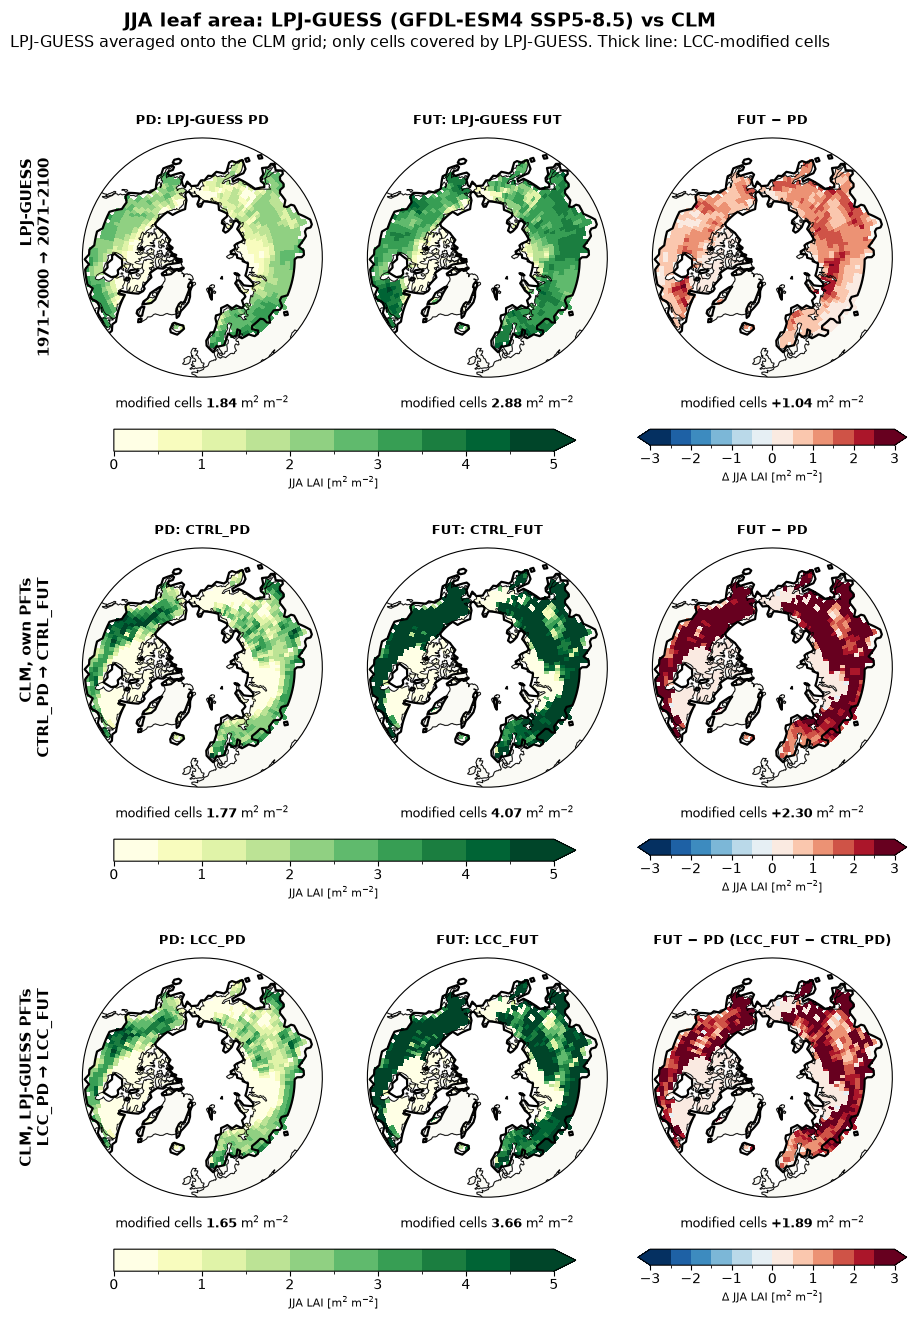

In [8]:
def outline_modified(ax, lw=1.6):
    data, lon_c = add_cyclic_point(modified.astype(float).values, coord=modified["lon"].values)
    ax.contour(lon_c, modified["lat"].values, data, levels=[0.5], colors="black", linewidths=lw,
               transform=ccrs.PlateCarree(), zorder=5)

jja = {name: summaries(mon)["JJA mean"] for name, mon in series.items()}
ROWS = [
    ("LPJ-GUESS\n1971–2000 → 2071–2100", "LPJ-GUESS PD (1971–2000)", "LPJ-GUESS FUT (2071–2100)"),
    ("CLM, own PFTs\nCTRL_PD → CTRL_FUT", "CTRL_PD", "CTRL_FUT"),
    ("CLM, LPJ-GUESS PFTs\nLCC_PD → LCC_FUT", "LCC_PD", "LCC_FUT"),
]
ABS_B = np.arange(0, 5.01, 0.5)
DIF_B = np.arange(-3, 3.01, 0.5)
cm_abs = plt.get_cmap("YlGn", len(ABS_B) - 1); cm_abs.set_over(cm_abs(cm_abs.N - 1))
cm_dif = plt.get_cmap("RdBu_r", len(DIF_B) - 1); cm_dif.set_over(cm_dif(cm_dif.N - 1)); cm_dif.set_under(cm_dif(0))

fig, axes = fm.map_grid(3, 3, left=1.6, titles_every_row=False, top_extra=0.45)
for i, (label, a, b) in enumerate(ROWS):
    d = jja[b] - (jja["CTRL_PD"] if i == 2 else jja[a])
    panels = [(jja[a], f"PD: {a.split(' (')[0]}", "abs"), (jja[b], f"FUT: {b.split(' (')[0]}", "abs"),
              (d, "FUT − PD" + (" (LCC_FUT − CTRL_PD)" if i == 2 else ""), "dif")]
    for j, (x, title, kind) in enumerate(panels):
        p, _, _ = fm.plot_single_boreal_panel(
            axes[i, j], x, title, units="m$^2$ m$^{-2}$", vmax=1.0, extent_lat=EXTENT_LAT, add_cbar=False,
            mean_lat_min=None, mean_text=f"modified cells {fm._bold(f'{wmean(x, modified & common):+.2f}' if kind == 'dif' else f'{wmean(x, modified & common):.2f}')}",
            mean_fontsize=9)
        bnd, cm = (ABS_B, cm_abs) if kind == "abs" else (DIF_B, cm_dif)
        p.set_cmap(cm); p.set_norm(mcolors.BoundaryNorm(bnd, cm.N))
        outline_modified(axes[i, j])
        if kind == "abs":
            pa = p
        else:
            pd_ = p
    axes[i, 0].text(-0.12, 0.5, label, transform=axes[i, 0].transAxes, rotation=90, ha="right", va="center",
                    fontsize=10.5, fontweight="semibold")
    fm._cbar_below(fig, axes[i, :2], pa, "JJA LAI [m$^2$ m$^{-2}$]", fm.CBAR_LABELSIZE_SHARED, extend="max")
    fm._cbar_below(fig, axes[i, 2], pd_, "Δ JJA LAI [m$^2$ m$^{-2}$]", fm.CBAR_LABELSIZE,
                   shrink=fm.CBAR_SHRINK, height=fm.CBAR_HEIGHT)
fm.add_suptitle(fig, "JJA leaf area: LPJ-GUESS (GFDL-ESM4 SSP5-8.5) vs CLM", None,
                subtitle="LPJ-GUESS averaged onto the CLM grid; only cells covered by LPJ-GUESS. Thick line: LCC-modified cells")
fig.savefig(OUT / "lai_jja_maps_clm_vs_lpjguess.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. What this shows (2026-11-19, CLM 2001–2025)

Evidence tags: **(a)** read from the outputs above, **(b)** inference, **(c)** unverified.

**1. The annual LPJ-GUESS file is the annual peak, not the mean (a).** Its `Total` matches the maximum of the 12 monthly values (r = 0.998) much better than their mean (r = 0.85); mean over cells 1.98 vs 1.96 (max) vs 1.17 (mean) in PD. Use the monthly files for mean LAI.

**2. PD: CLM and LPJ-GUESS agree (a).** LCC-modified cells: annual mean **1.15 vs 1.15** (CTRL_PD vs LPJ-GUESS 1971–2000), JJA 1.77 vs 1.84, seasonal peak 2.08 vs 1.95. LPJ-GUESS greens up earlier (June 1.6 vs 1.2) and browns earlier (October 1.0 vs 1.4).

**3. FUT: CLM's leaf area grows about twice as much (a).** JJA mean, modified cells:

| | PD | FUT | FUT − PD | FUT / PD |
|---|---|---|---|---|
| LPJ-GUESS (GFDL-ESM4 SSP5-8.5) | 1.84 | 2.88 | **+1.04** | **×1.57** |
| CLM, CTRL_PD → LCC_FUT (same change as LPJ-GUESS) | 1.77 | 3.66 | **+1.89** | **×2.07** |
| CLM, CTRL_PD → CTRL_FUT (CLM's own PFTs) | 1.77 | 4.07 | +2.30 | ×2.30 |

Same for the annual mean (×1.64 vs ×2.08) and the peak (×1.51 vs ×1.93). Winter LAI (evergreens) also doubles in CLM (0.7 → 1.5) but rises less in LPJ-GUESS (0.75 → 1.1).

**4. With the LPJ-GUESS PFTs, CLM grows less leaf area (a).** LCC_FUT − CTRL_FUT: JJA −0.41 (×0.90); LCC_PD − CTRL_PD: −0.12 (×0.94). The LPJ-GUESS cover has more deciduous trees, shrubs and grass than CLM's 2000 map.

**5. What it means for the emissions (b).** In MEGAN the leaf-area factor γL is nearly proportional to LAI at these low LAI values, and in CLM it roughly doubled from PD to FUT (emission-weighted γL ×2.0 in the modified cells). With LPJ-GUESS's LAI change (×1.57 instead of ×2.07) the future emissions would be up to ~25–30 % lower (2.07 / 1.57 = 1.32 if γL were exactly proportional; less where it saturates). That is a real part of the gap to Tang, but smaller than the missing CO₂ inhibition of monoterpenes (b). Why CLM's LAI grows more (CO₂ fertilisation at 1135 ppm, nitrogen limitation in LPJ-GUESS, warmer climate in our FUT) was not tested here (c).
